In [1]:
from pathlib import Path
from zipfile import ZipFile
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import confusion_matrix

SEED = 42
DATA_DIR = Path("dataset")
DATA_ARCHIVE = Path("alphabet.zip")

IMAGE_SIZE = 64
BATCH_SIZE = 32

TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
EXPECTED_CLASSES = [chr(code) for code in range(ord('A'), ord('Z') + 1)] + ['del', 'nothing', 'space']
EXPECTED_IMAGES_PER_CLASS = 3000


## 2. Dataset Utilities & Splitting


In [2]:
def locate_dataset_roots(data_dir):
    data_dir = Path(data_dir)
    train_candidates = [
        data_dir / 'train',
        data_dir / 'asl_alphabet_train' / 'asl_alphabet_train',
        data_dir / 'asl_alphabet_train',
        Path('asl_alphabet_train') / 'asl_alphabet_train',
    ]
    reference_candidates = [
        data_dir / 'asl_alphabet_test' / 'asl_alphabet_test',
        data_dir / 'asl_alphabet_test',
        Path('asl_alphabet_test') / 'asl_alphabet_test',
    ]
    train_root = next((path for path in train_candidates if path.is_dir()), None)
    reference_root = next((path for path in reference_candidates if path.is_dir()), None)
    return train_root, reference_root

def prepare_dataset(data_dir=DATA_DIR, archive_path=DATA_ARCHIVE):
    train_root, reference_root = locate_dataset_roots(data_dir)
    if train_root is not None:
        return train_root, reference_root
    archive_path = Path(archive_path)
    if not archive_path.is_file():
        raise FileNotFoundError(f'Place alphabet.zip beside the notebook or extract it inside {data_dir}')
    target = Path(data_dir).resolve()
    target.mkdir(parents=True, exist_ok=True)
    with ZipFile(archive_path) as archive:
        for member in archive.infolist():
            destination = (target / member.filename).resolve()
            try:
                destination.relative_to(target)
            except ValueError as error:
                raise ValueError(f'Unsafe archive path: {member.filename}') from error
        archive.extractall(target)
    train_root, reference_root = locate_dataset_roots(data_dir)
    if train_root is None:
        raise ValueError('The archive does not contain the expected ASL Alphabet training folders')
    return train_root, reference_root

def scan_image_folder(data_dir):
    data_dir = Path(data_dir)
    if not data_dir.exists():
        raise FileNotFoundError(f"Folder not found: {data_dir}")

    rows = []
    class_dirs = sorted([p for p in data_dir.iterdir() if p.is_dir()])
    if not class_dirs:
        raise ValueError(f"No class folders found inside {data_dir}")

    for class_dir in class_dirs:
        label = class_dir.name
        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({"path": str(image_path.as_posix()), "label": label})

    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError(f"No images found in {data_dir}")

    return df.sample(frac=1, random_state=SEED).reset_index(drop=True)

def scan_reference_folder(data_dir):
    if data_dir is None or not Path(data_dir).is_dir():
        return pd.DataFrame(columns=['path', 'label'])
    rows = []
    for image_path in sorted(Path(data_dir).iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            stem = image_path.stem
            label = stem[:-5] if stem.endswith('_test') else stem
            rows.append({'path': str(image_path.as_posix()), 'label': label})
    return pd.DataFrame(rows)

def split_dataset(df, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO, test_ratio=TEST_RATIO):
    if not np.isclose(train_ratio + val_ratio + test_ratio, 1.0):
        raise ValueError('Train, validation, and test ratios must sum to 1')
    if df['label'].value_counts().min() < 3:
        raise ValueError('Every class needs at least three images for a stratified split')
    train_df, remaining_df = train_test_split(
        df, test_size=val_ratio + test_ratio, random_state=SEED, shuffle=True, stratify=df['label']
    )
    relative_test_ratio = test_ratio / (val_ratio + test_ratio)
    val_df, test_df = train_test_split(
        remaining_df, test_size=relative_test_ratio, random_state=SEED, shuffle=True, stratify=remaining_df['label']
    )
    splits = [part.reset_index(drop=True) for part in (train_df, val_df, test_df)]
    expected_classes = set(df['label'].unique())
    if any(set(part['label'].unique()) != expected_classes for part in splits):
        raise ValueError('All classes must exist in every split')
    paths = [set(part['path']) for part in splits]
    if paths[0] & paths[1] or paths[0] & paths[2] or paths[1] & paths[2]:
        raise ValueError('Dataset split leakage detected')
    return tuple(splits)

def get_class_distribution(df):
    return df["label"].value_counts().rename_axis("label").reset_index(name="count").sort_values("label").reset_index(drop=True)

def sample_images_by_class(df, max_per_class=1):
    samples = []
    rng = random.Random(SEED)
    for label in sorted(df["label"].unique()):
        class_paths = df[df["label"] == label]["path"].tolist()
        rng.shuffle(class_paths)
        for path in class_paths[:max_per_class]:
            samples.append({"label": label, "path": path})
    return pd.DataFrame(samples)


## 3. PyTorch Dataset & DataLoaders


In [3]:
class SignLanguageDataset(Dataset):
    def __init__(self, dataframe, label_to_index=None, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        if label_to_index is None:
            labels = sorted(self.dataframe["label"].unique())
            self.label_to_index = {label: index for index, label in enumerate(labels)}
        else:
            self.label_to_index = label_to_index

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row["path"]).convert("RGB")
        label = self.label_to_index[row["label"]]
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

def get_train_transforms(image_size=IMAGE_SIZE):
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.95, 1.05)),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
    ])

def get_evaluation_transforms(image_size=IMAGE_SIZE):
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
    ])

def build_dataloaders(train_df, val_df, test_df, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE):
    label_to_index = {label: index for index, label in enumerate(sorted(train_df["label"].unique()))}
    expected_labels = set(label_to_index)
    if set(val_df['label'].unique()) != expected_labels or set(test_df['label'].unique()) != expected_labels:
        raise ValueError('Train, validation, and test class sets do not match')
    train_transform = get_train_transforms(image_size=image_size)
    evaluation_transform = get_evaluation_transforms(image_size=image_size)

    train_loader = DataLoader(SignLanguageDataset(train_df, label_to_index, train_transform), batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(SignLanguageDataset(val_df, label_to_index, evaluation_transform), batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    test_loader = DataLoader(SignLanguageDataset(test_df, label_to_index, evaluation_transform), batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

    return train_loader, val_loader, test_loader, label_to_index


## 4. Visualization Utilities


In [4]:
def plot_class_distribution(df, title="Class Distribution"):
    distribution = get_class_distribution(df)
    fig, ax = plt.subplots(figsize=(max(8, len(distribution) * 0.6), 5))
    ax.bar(distribution["label"], distribution["count"])
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Images")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    plt.show()

def plot_sample_grid(df, max_per_class=1):
    samples = sample_images_by_class(df, max_per_class=max_per_class)
    n = len(samples)
    if n == 0: return
    cols = min(5, n)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = [axes] if rows == 1 and cols == 1 else list(axes) if rows == 1 else axes.flatten()
    
    for ax, (_, row) in zip(axes, samples.iterrows()):
        ax.imshow(Image.open(row["path"]).convert("RGB"))
        ax.set_title(row["label"])
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Random Sample from Each Class", y=1.02)
    fig.tight_layout()
    plt.show()


## 5. Model Architecture & Training Loop


In [5]:
class SignLanguageCNN(nn.Module):
    def __init__(self, num_classes):
        super(SignLanguageCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.nnl1 = nn.Linear(128 * 8 * 8, 512)
        self.dropout = nn.Dropout(0.5)
        self.nnl2 = nn.Linear(512, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = torch.flatten(x, 1)
        x = self.relu(self.nnl1(x))
        x = self.dropout(x)
        x = self.nnl2(x)
        return x

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, device='cuda'):
    model.to(device)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_state = None
    
    for epoch in range(num_epochs):
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct_train / total_train
        
        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                
        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = correct_val / total_val
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        
        print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")
              
    model.load_state_dict(best_state)
    model.to(device)
    return history

def plot_learning_curves(history):
    epochs = range(1, len(history['train_loss']) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label='Train Loss')
    plt.plot(epochs, history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], label='Train Accuracy')
    plt.plot(epochs, history['val_acc'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.tight_layout()
    plt.show()

def evaluate_and_plot_confusion_matrix(model, test_loader, class_names, device='cuda'):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    test_accuracy = float(np.mean(np.asarray(all_preds) == np.asarray(all_labels)))
    print(f'Test Accuracy: {test_accuracy:.4f}')
    cm = confusion_matrix(all_labels, all_preds, labels=range(len(class_names)))
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix on Test Set')
    plt.show()
    return test_accuracy, cm

def evaluate_reference_accuracy(model, reference_df, label_to_index, device='cuda'):
    known_reference = reference_df[reference_df['label'].isin(label_to_index)].reset_index(drop=True)
    if known_reference.empty:
        return None
    dataset = SignLanguageDataset(known_reference, label_to_index, get_evaluation_transforms())
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    model.eval()
    correct = 0
    with torch.no_grad():
        for inputs, labels in loader:
            predictions = model(inputs.to(device)).argmax(dim=1).cpu()
            correct += int((predictions == labels).sum())
    accuracy = correct / len(dataset)
    print(f'Reference Accuracy ({len(dataset)} images): {accuracy:.4f}')
    return accuracy


## 6. Main Pipeline Execution


Using device: cpu
Training image root: dataset\asl_alphabet_train\asl_alphabet_train
Total classified images: 87000
Classes (29): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
External reference images: 28


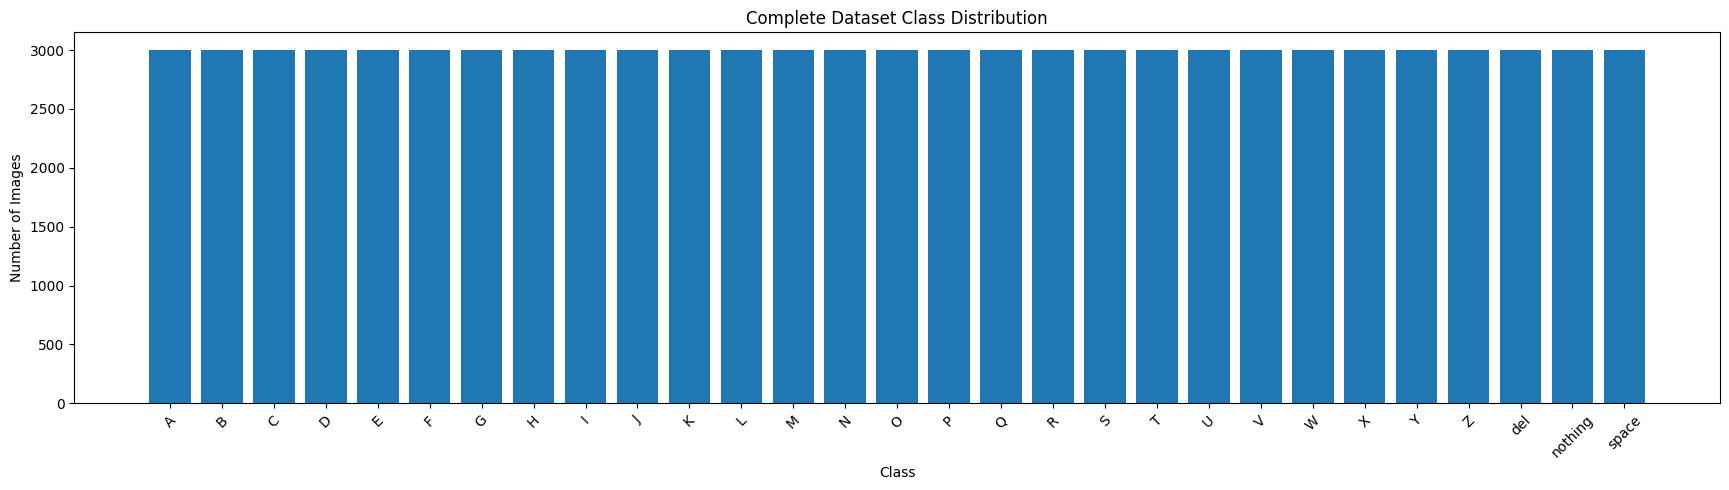

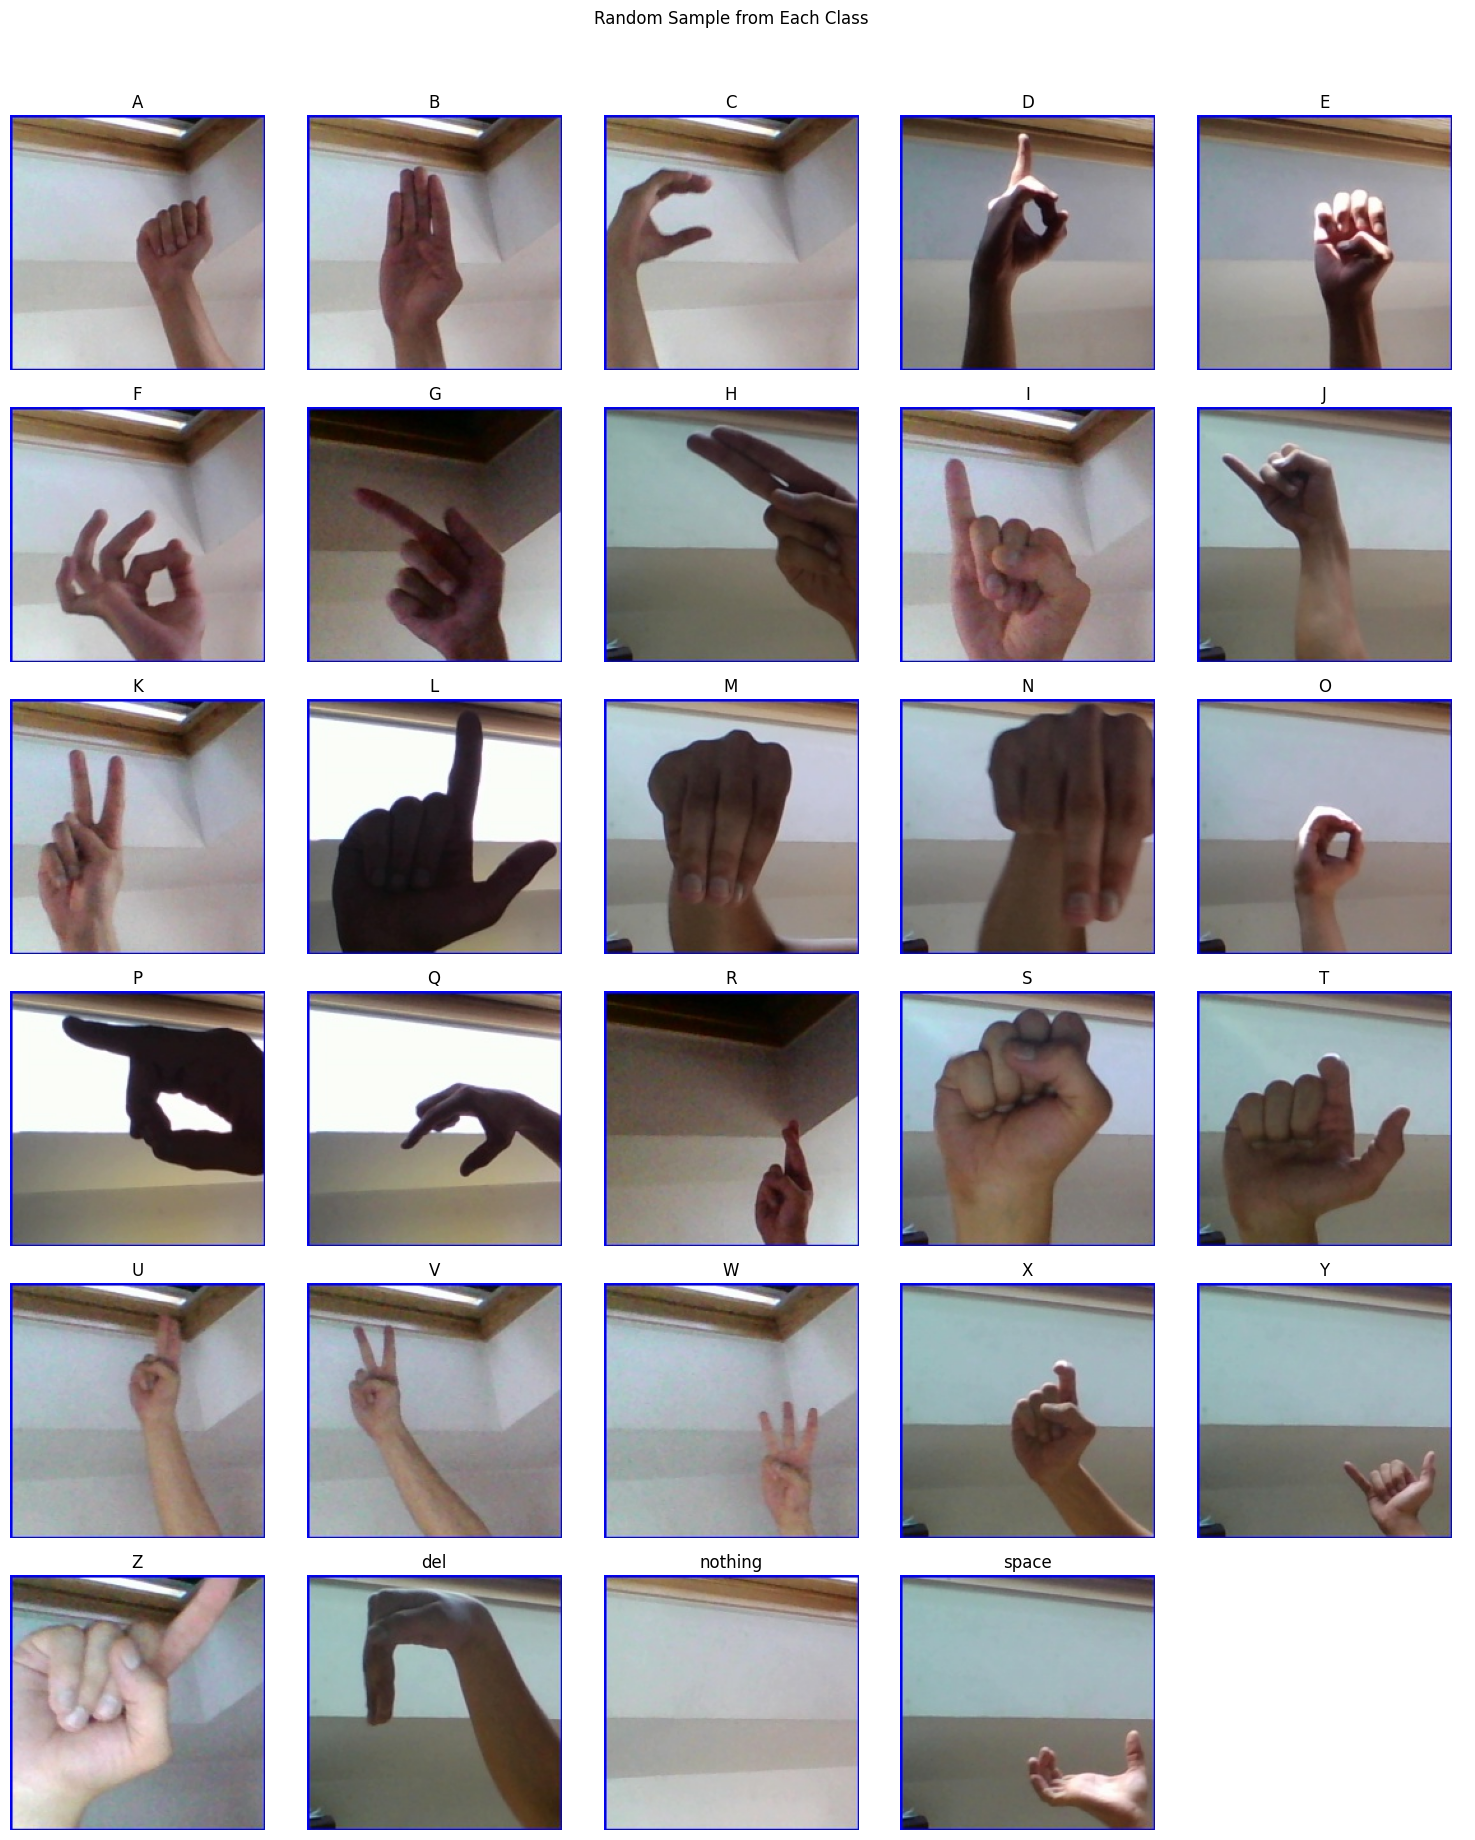

Final splits -> Train: 69600, Validation: 8700, Test: 8700

Starting training...


In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

train_root, reference_root = prepare_dataset()
print(f'Training image root: {train_root}')
full_df = scan_image_folder(train_root)
reference_df = scan_reference_folder(reference_root)
class_names_found = sorted(full_df['label'].unique())
class_counts = full_df['label'].value_counts()
if set(class_names_found) != set(EXPECTED_CLASSES):
    raise ValueError(f'Unexpected classes: {class_names_found}')
if not (class_counts == EXPECTED_IMAGES_PER_CLASS).all():
    raise ValueError(f'Incomplete class folders: {class_counts.to_dict()}')
if not {'nothing', 'background', 'blank', 'no_gesture'} & {name.casefold() for name in class_names_found}:
    raise ValueError('A blank class is required for Phase 3')
print(f'Total classified images: {len(full_df)}')
print(f'Classes ({len(class_names_found)}): {class_names_found}')
print(f'External reference images: {len(reference_df)}')

plot_class_distribution(full_df, title='Complete Dataset Class Distribution')
plot_sample_grid(full_df, max_per_class=1)

train_df, val_df, test_df = split_dataset(full_df)
print(f'Final splits -> Train: {len(train_df)}, Validation: {len(val_df)}, Test: {len(test_df)}')

train_loader, val_loader, test_loader, label_to_index = build_dataloaders(
    train_df, val_df, test_df, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)
class_names = list(label_to_index.keys())

model = SignLanguageCNN(num_classes=len(class_names))
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("\nStarting training...")
history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, device=device)

plot_learning_curves(history)
test_accuracy, confusion = evaluate_and_plot_confusion_matrix(model, test_loader, class_names, device=device)
reference_accuracy = evaluate_reference_accuracy(model, reference_df, label_to_index, device=device)
checkpoint = {
    'model_state_dict': {key: value.detach().cpu() for key, value in model.state_dict().items()},
    'class_names': class_names,
    'architecture': 'sign_language_cnn',
    'image_size': IMAGE_SIZE,
    'mean': [0.0, 0.0, 0.0],
    'std': [1.0, 1.0, 1.0],
    'test_accuracy': test_accuracy,
    'reference_accuracy': reference_accuracy,
    'split_ratios': [TRAIN_RATIO, VAL_RATIO, TEST_RATIO],
    'seed': SEED
}
torch.save(checkpoint, 'weights.pth')
print('Saved Phase 2 checkpoint to weights.pth')
